<div style="text-align: center; font-weight: 600;">
  <img src="kyu-logo.png" alt="Kyambogo University logo" style="width: 110px; height: auto; margin: 4px 0 12px;">
  <div style="margin: 6px 0 18px;">KYAMBOGO UNIVERSITY</div>
  <div style="margin: 14px 0;">SCHOOL OF COMPUTING AND INFORMATION SCIENCE</div>
  <div style="margin: 14px 0;">DEPARTMENT OF COMPUTER SCIENCE</div>
  <div style="margin: 14px 0;">BACHELOR OF INFORMATION TECHNOLOGY AND COMPUTING</div>
  <div style="margin: 18px 0;">4SCS2102 NUMERICAL ANALYSIS AND COMPUTATION</div>
  <div style="margin: 18px 0;">PROJECT: TEMPERATURE PREDICTION USING THE FINITE DIFFERENCE METHOD</div>
  <div style="margin: 14px auto; max-width: 720px;">Estimate missing temperature values for days in a weekly dataset recorded at 2-day intervals.</div>
  <div style="margin: 14px 0;">MR. MATOVU HENRY</div>
  <div style="margin: 14px 0;">GROUP 3</div>
  <div style="margin: 14px 0;">YEAR OF STUDY: 2026</div>
  <div style="margin: 14px 0 22px;">DATE OF SUBMISSION: 5 NOVEMBER 2026</div>
  <div style="margin: 14px 0;">GROUP MEMBERS</div>
</div>

<table style="width: 100%; border-collapse: collapse; text-align: left; font-weight: 600;">
  <thead>
    <tr>
      <th style="padding: 8px; border: 1px solid #d5dce5; width: 10%;">No.</th>
      <th style="padding: 8px; border: 1px solid #d5dce5;">Name</th>
      <th style="padding: 8px; border: 1px solid #d5dce5; width: 38%;">Registration Number</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">1</td><td style="padding: 6px; border: 1px solid #d5dce5;">Muzaaya Joseph</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITE/06694/PE</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">2</td><td style="padding: 6px; border: 1px solid #d5dce5;">Carlos Muhumuza</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITD/11361/PD</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">3</td><td style="padding: 6px; border: 1px solid #d5dce5;">Magembe Duncan Ronald</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITE/11343/PD</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">4</td><td style="padding: 6px; border: 1px solid #d5dce5;">Kaaki Richard</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITE/11293/PE</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">5</td><td style="padding: 6px; border: 1px solid #d5dce5;">Lugarego Isaac</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITD/324/GV</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">6</td><td style="padding: 6px; border: 1px solid #d5dce5;">Agaba Abel</td><td style="padding: 6px; border: 1px solid #d5dce5;">25/U/ITE/19548/PE</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">7</td><td style="padding: 6px; border: 1px solid #d5dce5;">Ebil Paul</td><td style="padding: 6px; border: 1px solid #d5dce5;">26/U/ITE/21899/PE</td></tr>
    <tr><td style="padding: 6px; border: 1px solid #d5dce5;">8</td><td style="padding: 6px; border: 1px solid #d5dce5;">Edyangu Joshua</td><td style="padding: 6px; border: 1px solid #d5dce5;">26/U/ITE/21900/PE</td></tr>
  </tbody>
</table>


## 1. Introduction and choice of language

Numerical analysis uses computational procedures to approximate mathematical quantities. This project applies interpolation to estimate temperatures on days without a recorded measurement.

| Consideration | MATLAB | Python |
|---|---|---|
| Cost and access | Commercial product; access depends on a licence | Free and open-source |
| Numerical computing | Strong matrix and technical-computing environment | NumPy and SciPy provide numerical tools |
| Data and plots | Integrated technical-computing workflow | Pandas and Matplotlib support tables and plots |
| Extensibility | MATLAB toolboxes and its technical ecosystem | Broad ecosystem and general-purpose language |
| Choice for this project | Good option where a licence is available | **Selected:** accessible, readable, and suitable for implementing the formula directly |

Both languages can solve this problem. Python is selected because it is freely available and its libraries make it practical to show calculations, tables, tests, and plots in one notebook. The interpolation method itself is implemented below rather than delegated to an interpolation package.


## 1. Numerical method

For equally spaced data, the Gregory–Newton forward formula estimates a function value from the initial observation and its forward differences [1]:

$$
f_p = f_0 + p\Delta f_0 + \frac{p(p-1)}{2!}\Delta^2 f_0 + \cdots,
\qquad p = \frac{x-x_0}{h}.
$$

Here, $p=(x-x_0)/h$ is the position of the target relative to the starting point, and $h$ is the constant spacing between successive $x$-values. The forward-difference table supplies the terms used in the estimate. The implementation and results are presented in the following sections.


## 2. Problem and dataset

The coursework asks for estimates on days between weekly measurements taken every two days. The following dataset is **hypothetical**; these values are not claimed to be observed weather data.

| Day | Temperature (°C) | Availability |
|---:|---:|---|
| 1 | 24.0 | Recorded |
| 2 | — | Missing |
| 3 | 27.0 | Recorded |
| 4 | — | Missing |
| 5 | 30.0 | Recorded |
| 6 | — | Missing |
| 7 | 32.0 | Recorded |

The known x-values are equally spaced: $1, 3, 5, 7$, with spacing $h=2$ days. The missing values lie inside the recorded range, so this is interpolation rather than extrapolation.


## 3. Mathematical background

For equally spaced data, the first forward difference is

$$
\Delta y_i = y_{i+1} - y_i.
$$

Higher differences are obtained by repeatedly differencing the previous row. Newton's forward interpolation formula is

$$
f(x) = f_0 + p\Delta f_0 + \frac{p(p-1)}{2!}\Delta^2 f_0 + \frac{p(p-1)(p-2)}{3!}\Delta^3 f_0 + \cdots.
$$

Here, $p=(x-x_0)/h$, $x_0$ is the first tabulated x-value, and $h$ is the common spacing. Forward differences are convenient near the start of a table. Newton's backward formula uses $q=(x-x_n)/h$ and the last entries of each difference row, making it convenient near the end.

For a polynomial of degree at most $n$, its $(n+1)$-st differences are zero apart from possible floating-point roundoff, so interpolation reproduces that polynomial exactly in exact arithmetic. For a sufficiently smooth function and an interpolation polynomial $P_n$ through nodes $x_0,\ldots,x_n$, the remainder is

$$
f(x)-P_n(x)=\frac{f^{(n+1)}(\xi)}{(n+1)!}\prod_{i=0}^{n}(x-x_i),
$$

for some $\xi$ in the interval containing the nodes and the target. Thus, for cubic interpolation at a fixed target, the product of the four node offsets scales as $h^4$, explaining the observed $O(h^4)$ error when $f^{(4)}$ remains bounded. For a general smooth function, interpolation error depends on the function, spacing, and degree.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

days = np.array([1.0, 3.0, 5.0, 7.0])
temperatures = np.array([24.0, 27.0, 30.0, 32.0])
all_days = np.arange(1.0, 8.0)
missing_days = np.array([2.0, 4.0, 6.0])

display(pd.DataFrame({"Day": days.astype(int), "Temperature (°C)": temperatures}))


,Day,Temperature (°C)
0,1,24.0
1,3,27.0
2,5,30.0
3,7,32.0


## 4. Helper functions

The functions below implement the difference table and both Newton interpolation forms. Input checks ensure the method is applied only to paired, finite, strictly increasing, equally spaced data. Unsuitable inputs raise a meaningful `ValueError`.


In [2]:
def forward_difference_table(values):
    """Return every forward-difference row for a 1D sequence of values."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or values.size == 0:
        raise ValueError("values must be a non-empty one-dimensional sequence.")
    if not np.all(np.isfinite(values)):
        raise ValueError("values must all be finite numbers.")
    table = [values]
    while len(table[-1]) > 1:
        previous_row = table[-1]
        table.append(previous_row[1:] - previous_row[:-1])
    return table


def _validate_interpolation_data(x_points, y_points):
    """Validate interpolation inputs and return arrays plus common spacing."""
    x_points = np.asarray(x_points, dtype=float)
    y_points = np.asarray(y_points, dtype=float)
    if x_points.ndim != 1 or y_points.ndim != 1:
        raise ValueError("x_points and y_points must be one-dimensional.")
    if x_points.size != y_points.size:
        raise ValueError("x_points and y_points must have the same length.")
    if x_points.size < 2:
        raise ValueError("At least two data pairs are required.")
    if not np.all(np.isfinite(x_points)) or not np.all(np.isfinite(y_points)):
        raise ValueError("All data points must be finite numbers.")
    spacings = np.diff(x_points)
    if np.any(spacings <= 0):
        raise ValueError("x_points must be strictly increasing.")
    if not np.allclose(spacings, spacings[0], rtol=1e-9, atol=1e-12):
        raise ValueError("Newton interpolation requires equally spaced x_points.")
    return x_points, y_points, float(spacings[0])


def newton_forward_interpolation(x_value, x_points, y_points):
    """Estimate f(x_value) using Newton's forward-difference formula."""
    x_points, y_points, h = _validate_interpolation_data(x_points, y_points)
    if not np.isfinite(x_value):
        raise ValueError("x_value must be finite.")
    p = (float(x_value) - x_points[0]) / h
    differences = forward_difference_table(y_points)
    estimate = differences[0][0]
    for order in range(1, len(differences)):
        product = math.prod(p - k for k in range(order))
        estimate += product * differences[order][0] / math.factorial(order)
    return float(estimate)


def newton_backward_interpolation(x_value, x_points, y_points):
    """Estimate f(x_value) using Newton's backward-difference formula."""
    x_points, y_points, h = _validate_interpolation_data(x_points, y_points)
    if not np.isfinite(x_value):
        raise ValueError("x_value must be finite.")
    q = (float(x_value) - x_points[-1]) / h
    differences = forward_difference_table(y_points)
    estimate = differences[0][-1]
    for order in range(1, len(differences)):
        product = math.prod(q + k for k in range(order))
        estimate += product * differences[order][-1] / math.factorial(order)
    return float(estimate)


## 5. Forward-difference table

Each difference is placed in the row beginning at the same recorded point as its leading value. Blank cells mean that no difference of that order begins at that row.


In [3]:
difference_rows = forward_difference_table(temperatures)
headers = ["Day (x)", "Temperature f(x)"] + ["Δf" if order == 1 else f"Δ^{order}f" for order in range(1, len(difference_rows))]
rows = []
for row_index, day in enumerate(days):
    row = [int(day), temperatures[row_index]]
    for order in range(1, len(difference_rows)):
        row.append(difference_rows[order][row_index] if row_index < len(difference_rows[order]) else np.nan)
    rows.append(row)

difference_table = pd.DataFrame(rows, columns=headers)
rounded_table = difference_table.round(2)
display(rounded_table.astype(object).where(rounded_table.notna(), ""))


,Day (x),Temperature f(x),Δf,Δ^2f,Δ^3f
0,1,24.0,3.0,0.0,-1.0
1,3,27.0,3.0,-1.0,
2,5,30.0,2.0,,
3,7,32.0,,,


The leading differences are $\Delta f_0=3$, $\Delta^2 f_0=0$, and $\Delta^3 f_0=-1$. A nonzero third difference means the interpolating polynomial is cubic rather than quadratic.

## 6. Estimate the missing temperatures

For Day 2, $x_0=1$, $h=2$, and $p=(2-1)/2=0.5$. Substitution gives

$$
\begin{aligned}
f(2) &= 24 + 0.5(3) + \frac{0.5(-0.5)}{2}(0) + \frac{0.5(-0.5)(-1.5)}{6}(-1) \\
     &= 25.4375\ ^\circ\mathrm{C}.
\end{aligned}
$$

For Day 4, $p=(4-1)/2=1.5$:

$$
\begin{aligned}
f(4) &= 24 + 1.5(3) + \frac{1.5(0.5)}{2}(0) + \frac{1.5(0.5)(-0.5)}{6}(-1) \\
     &= 24 + 4.5 + 0 + 0.0625 \\
     &= 28.5625\ ^\circ\mathrm{C}.
\end{aligned}
$$

The code applies the same formula to Day 6. Intermediate values are not rounded; rounding is only for display.


In [4]:
forward_estimates = {
    float(day): newton_forward_interpolation(day, days, temperatures)
    for day in missing_days
}

weekly_rows = []
recorded = dict(zip(days, temperatures))
for day in all_days:
    if day in recorded:
        value, status = recorded[day], "Recorded"
    else:
        value, status = forward_estimates[day], "Estimated"
    weekly_rows.append({"Day": int(day), "Temperature (°C)": value, "Status": status})

weekly_report = pd.DataFrame(weekly_rows)
display(weekly_report.round({"Temperature (°C)": 2}))


,Day,Temperature (°C),Status
0,1,24.00,Recorded
1,2,25.44,Estimated
2,3,27.00,Recorded
3,4,28.56,Estimated
4,5,30.00,Recorded
5,6,31.19,Estimated
6,7,32.00,Recorded


## 7. Forward and backward formula comparison

Forward interpolation is convenient near the first observation; backward interpolation is convenient near the last. Using all four data points, both formulas represent the same interpolating polynomial and should agree up to floating-point rounding. This comparison does not imply separate measurements.


In [5]:
comparison_rows = []
for day in missing_days:
    forward_value = newton_forward_interpolation(day, days, temperatures)
    backward_value = newton_backward_interpolation(day, days, temperatures)
    comparison_rows.append({
        "Missing day": int(day),
        "Forward estimate (°C)": forward_value,
        "Backward estimate (°C)": backward_value,
        "Absolute difference (°C)": abs(forward_value - backward_value),
    })
formula_comparison = pd.DataFrame(comparison_rows)
display(formula_comparison.round(8))


,Missing day,Forward estimate (°C),Backward estimate (°C),Absolute difference (°C)
0,2,25.4375,25.4375,0.0
1,4,28.5625,28.5625,0.0
2,6,31.1875,31.1875,0.0


## 8. Independent analytical validation

The coursework readings define their own interpolating polynomial. Checking estimates against that same polynomial is a consistency check, not an independent accuracy test. Instead, we sample separate known functions at equally spaced points and compare the interpolated result with exact values between those points.

Linear, quadratic, and cubic polynomials up to degree three should be recovered to floating-point precision. A sine function is included to show that a cubic interpolant does not generally reproduce a non-polynomial function exactly.


In [6]:
validation_functions = {
    "Linear: 2 + 3x": lambda x: 2 + 3 * x,
    "Quadratic: 20 + 2x + 0.5x²": lambda x: 20 + 2 * x + 0.5 * x**2,
    "Cubic: 1 - x + 0.5x² - 0.1x³": lambda x: 1 - x + 0.5 * x**2 - 0.1 * x**3,
    "Sine: sin(x)": np.sin,
}
validation_x = np.array([0.0, 1.0, 2.0, 3.0])
validation_targets = [0.5, 1.5, 2.5]
validation_rows = []
for model_name, model in validation_functions.items():
    observed = model(validation_x)
    for target in validation_targets:
        estimate = newton_forward_interpolation(target, validation_x, observed)
        exact = float(model(target))
        validation_rows.append({
            "Model": model_name, "x": target, "Interpolated": estimate,
            "Exact": exact, "Absolute error": abs(estimate - exact),
        })
validation_table = pd.DataFrame(validation_rows)
validation_table["Absolute error (scientific)"] = validation_table["Absolute error"].map(lambda error: f"{error:.2e}")
display(validation_table.drop(columns="Absolute error").round(8))


,Model,x,Interpolated,Exact,Absolute error (scientific)
0,Linear: 2 + 3x,0.5,3.500000,3.500000,0.00e+00
1,Linear: 2 + 3x,1.5,6.500000,6.500000,0.00e+00
2,Linear: 2 + 3x,2.5,9.500000,9.500000,0.00e+00
3,Quadratic: 20 + 2x + 0.5x²,0.5,21.125000,21.125000,0.00e+00
4,Quadratic: 20 + 2x + 0.5x²,1.5,24.125000,24.125000,0.00e+00
5,Quadratic: 20 + 2x + 0.5x²,2.5,28.125000,28.125000,0.00e+00
6,Cubic: 1 - x + 0.5x² - 0.1x³,0.5,0.612500,0.612500,1.11e-16
7,Cubic: 1 - x + 0.5x² - 0.1x³,1.5,0.287500,0.287500,5.55e-17
8,Cubic: 1 - x + 0.5x² - 0.1x³,2.5,0.062500,0.062500,2.22e-16
9,Sine: sin(x),0.5,0.513544,0.479426,3.41e-02


For the polynomial models, errors should be close to floating-point roundoff. Sine errors are nonzero because the finite-degree interpolating polynomial only approximates sine between the nodes.

## 9. Number of terms and confidence in accuracy

When the difference table does not reach a zero column, the number of terms included affects the estimate. This experiment evaluates a sine-data example at $x=0.15$, using the tabulated values in [1]. The calculation uses $x_0=0.1$, $h=0.1$, and $p=0.5$. Since the tabulated sine values are rounded to six decimal places, the estimate uses those rounded values; the comparison value is the exact $\sin(0.15)$.

The table compares estimates obtained with successive numbers of terms against $\sin(0.15)$. With three terms, the $\Delta^2 f_0$ contribution is approximately $0.000248$; this contribution is distinct from the total absolute error, which is approximately $6.1\times10^{-5}$. For rounded or noisy data, adding terms does not necessarily reduce the error monotonically, so the error column provides an independent accuracy check.


In [7]:
def forward_interp_truncated(x_value, x_points, y_points, n_terms):
    """Evaluate Newton forward interpolation using only the first n terms."""
    x_points, y_points, _ = _validate_interpolation_data(x_points, y_points)
    if not isinstance(n_terms, (int, np.integer)) or not 1 <= n_terms <= len(x_points):
        raise ValueError("n_terms must be an integer between 1 and the number of data points.")
    if not np.isfinite(x_value):
        raise ValueError("x_value must be finite.")

    p = (float(x_value) - x_points[0]) / (x_points[1] - x_points[0])
    differences = forward_difference_table(y_points)
    estimate = 0.0
    for order in range(n_terms):
        coefficient = math.prod(p - k for k in range(order)) / math.factorial(order)
        estimate += coefficient * differences[order][0]
    return float(estimate)


sine_example_x = np.arange(0.0, 0.6, 0.1)
sine_example_y = np.round(np.sin(sine_example_x), 6)
sine_example_differences = forward_difference_table(sine_example_y)
sine_example_rows = []
for row_index, x_value in enumerate(sine_example_x):
    row = [x_value, sine_example_y[row_index]]
    for order in range(1, len(sine_example_differences)):
        row.append(sine_example_differences[order][row_index] if row_index < len(sine_example_differences[order]) else np.nan)
    sine_example_rows.append(row)
sine_example_difference_table = pd.DataFrame(
    sine_example_rows,
    columns=["x", "f(x)", "Δf", "Δ²f", "Δ³f", "Δ⁴f", "Δ⁵f"],
)
rounded_sine_example_table = sine_example_difference_table.round(6)
display(rounded_sine_example_table.astype(object).where(rounded_sine_example_table.notna(), ""))

# Evaluate from x0 = 0.1 (p = 0.5), rather than from the x = 0 row.
sine_example_nodes = sine_example_x[1:]
sine_example_values = sine_example_y[1:]
target = 0.15
exact = float(np.sin(target))
term_rows = []
for number_of_terms in range(1, len(sine_example_nodes) + 1):
    estimate = forward_interp_truncated(target, sine_example_nodes, sine_example_values, number_of_terms)
    term_rows.append({
        "Terms kept": number_of_terms,
        "Estimate": estimate,
        "Exact sin(0.15)": exact,
        "Absolute error": abs(estimate - exact),
    })
terms_error_table = pd.DataFrame(term_rows)
terms_error_table["Absolute error (scientific)"] = terms_error_table["Absolute error"].map(lambda error: f"{error:.3e}")
display(terms_error_table.drop(columns="Absolute error").round(8))


,x,f(x),Δf,Δ²f,Δ³f,Δ⁴f,Δ⁵f
0,0.0,0.0,0.099833,-0.000997,-0.000988,0.00002,0.000011
1,0.1,0.099833,0.098836,-0.001985,-0.000968,0.000031,
2,0.2,0.198669,0.096851,-0.002953,-0.000937,,
3,0.3,0.29552,0.093898,-0.00389,,,
4,0.4,0.389418,0.090008,,,,
5,0.5,0.479426,,,,,


,Terms kept,Estimate,Exact sin(0.15),Absolute error (scientific)
0,1,0.099833,0.149438,4.961e-02
1,2,0.149251,0.149438,1.871e-04
2,3,0.149499,0.149438,6.099e-05
3,4,0.149439,0.149438,4.925e-07
4,5,0.149437,0.149438,7.184e-07


,h,Target x,Absolute error,Observed order
0,1.0000,0.15,3.222150e-03,NaN
1,0.5000,0.15,2.143900e-04,3.909721
2,0.2500,0.15,1.361000e-05,3.977451
3,0.1250,0.15,8.500000e-07,3.994364
4,0.0625,0.15,5.000000e-08,3.998591


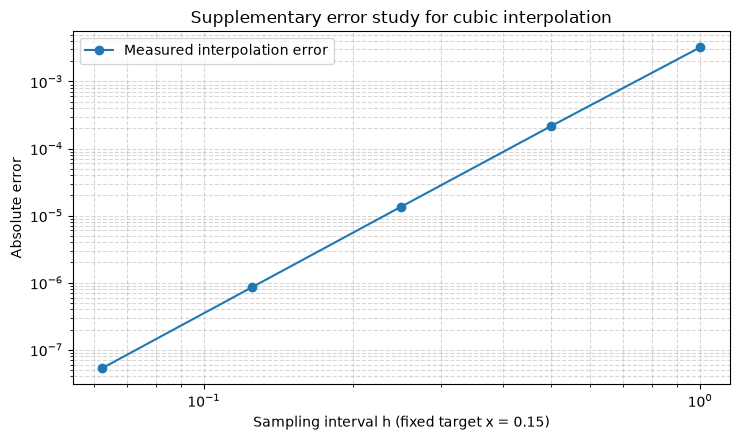

In [8]:
# Supplementary spacing study: hold the evaluation point fixed at x=0.15.
fixed_target = 0.15
step_sizes = np.array([1.0, 0.5, 0.25, 0.125, 0.0625])
spacing_rows = []
for h in step_sizes:
    sample_x = fixed_target + h * np.array([-1.5, -0.5, 0.5, 1.5])
    estimate = newton_forward_interpolation(fixed_target, sample_x, np.sin(sample_x))
    exact_value = float(np.sin(fixed_target))
    spacing_rows.append({"h": h, "Target x": fixed_target, "Absolute error": abs(estimate - exact_value)})
spacing_error_table = pd.DataFrame(spacing_rows)
spacing_error_table["Observed order"] = np.nan
for index in range(1, len(spacing_error_table)):
    previous_error = spacing_error_table.loc[index - 1, "Absolute error"]
    current_error = spacing_error_table.loc[index, "Absolute error"]
    spacing_error_table.loc[index, "Observed order"] = np.log(previous_error / current_error) / np.log(
        spacing_error_table.loc[index - 1, "h"] / spacing_error_table.loc[index, "h"]
    )
display(spacing_error_table.round(8))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(spacing_error_table["h"], spacing_error_table["Absolute error"], "o-", label="Measured interpolation error")
ax.set_xlabel("Sampling interval h (fixed target x = 0.15)")
ax.set_ylabel("Absolute error")
ax.set_title("Supplementary error study for cubic interpolation")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()


In this supplementary experiment, the target remains fixed at $x=0.15$ while four equally spaced nodes are moved closer to it. The observed order approaches four, consistent with the classical $O(h^4)$ error for cubic interpolation at a fixed target. The earlier order-five observation arose when the target moved towards zero with $h$; because the fourth derivative of sine is also small near zero, this setup introduced an additional factor of $h$. The terms-versus-error experiment above provides a complementary assessment using rounded sine values [1].


## 10. Unit tests and input validation

Each test has a known expected result. Two use worked interpolation examples from [1] to check the implementation against independent reference values. The remaining tests assess polynomial recovery, edge cases, the truncated-term helper, agreement between forward and backward formulas, and rejection of unsuitable inputs. A failed check raises an assertion or `ValueError`; the success message is displayed only when all checks pass.


In [9]:
def run_unit_tests():
    table = forward_difference_table([24, 27, 30, 32])
    assert np.allclose(table[1], [3, 3, 2])
    assert np.allclose(table[2], [0, -1])
    assert np.allclose(table[3], [-1])

    x = np.array([0.0, 1.0, 2.0, 3.0])
    test_functions = [
        lambda z: 2 + 2 * z,
        lambda z: 1 + z + z**2,
        lambda z: 1 - z + 0.5 * z**2 - 0.1 * z**3,
    ]
    for function in test_functions:
        expected = float(function(1.5))
        values = function(x)
        assert np.isclose(newton_forward_interpolation(1.5, x, values), expected)
        assert np.isclose(newton_backward_interpolation(1.5, x, values), expected)

    # Worked example 2 from [1]: interpolate at x = 5.5.
    example_2_x = np.array([2.0, 4.0, 6.0, 8.0, 10.0])
    example_2_y = np.array([14.0, 88.0, 274.0, 620.0, 1174.0])
    assert np.isclose(newton_forward_interpolation(5.5, example_2_x, example_2_y), 214.375)

    # Worked example 3 from [1]: interpolate at x = -1.
    example_3_x = np.array([-4.0, -2.0, 0.0, 2.0, 4.0, 6.0, 8.0])
    example_3_y = np.array([541.0, 55.0, 1.0, -53.0, -155.0, 31.0, 1225.0])
    assert np.isclose(newton_forward_interpolation(-1.0, example_3_x, example_3_y), 10.0, atol=1e-9)

    # Smallest valid dataset, negative values, and an extrapolation example.
    assert np.isclose(newton_forward_interpolation(0.5, [0, 1], [10, 20]), 15.0)
    assert np.isclose(newton_forward_interpolation(1.5, [0, 1, 2], [-1, 1, 3]), 2.0)
    assert np.isclose(newton_forward_interpolation(4.0, [0, 1, 2, 3], [0, 1, 4, 9]), 16.0)

    # Truncated interpolation accepts valid term counts and rejects invalid ones.
    assert np.isclose(forward_interp_truncated(1.5, x, 2 + 2 * x, 2), 5.0)
    invalid_term_counts = [0, len(x) + 1, 2.5]
    for term_count in invalid_term_counts:
        try:
            forward_interp_truncated(1.5, x, 2 + 2 * x, term_count)
        except ValueError:
            continue
        raise AssertionError("An invalid term count was not rejected.")

    for day in missing_days:
        assert np.isclose(
            newton_forward_interpolation(day, days, temperatures),
            newton_backward_interpolation(day, days, temperatures),
        )

    invalid_inputs = [
        lambda: newton_forward_interpolation(1, [0, 1, 3], [0, 1, 9]),
        lambda: newton_forward_interpolation(1, [1, 0], [1, 0]),
        lambda: newton_forward_interpolation(1, [0], [1]),
        lambda: newton_forward_interpolation(1, [0, 1], [0]),
        lambda: newton_forward_interpolation(np.nan, [0, 1], [0, 1]),
        lambda: forward_difference_table([]),
    ]
    for invalid_call in invalid_inputs:
        try:
            invalid_call()
        except ValueError:
            continue
        raise AssertionError("An invalid interpolation input was not rejected.")
    return "All unit tests passed."

print(run_unit_tests())


All unit tests passed.


## 11. Measurement sensitivity and numerical considerations

Interpolation can be affected by errors in the recorded readings. The next calculation changes one measurement by 0.1°C and displays the resulting changes in the estimates. This is an illustration, not a statistical uncertainty model.

Do not round intermediate differences or formula terms; round only final report values. Higher-degree interpolants and extrapolation can amplify measurement and floating-point errors, so estimates should be interpreted in the context of data quality and the physical behavior of temperature.


In [10]:
perturbed_temperatures = temperatures.copy()
perturbed_temperatures[1] += 0.1
sensitivity_rows = []
for day in missing_days:
    baseline = newton_forward_interpolation(day, days, temperatures)
    perturbed = newton_forward_interpolation(day, days, perturbed_temperatures)
    sensitivity_rows.append({
        "Missing day": int(day),
        "Original estimate (°C)": baseline,
        "After +0.1°C at Day 3": perturbed,
        "Change (°C)": perturbed - baseline,
    })
display(pd.DataFrame(sensitivity_rows).round(4))


,Missing day,Original estimate (°C),After +0.1°C at Day 3,Change (°C)
0,2,25.4375,25.5313,0.0938
1,4,28.5625,28.6188,0.0563
2,6,31.1875,31.1562,-0.0312


## 12. Temperature profile

The line joins the recorded values and interpolation estimates. It visualizes this polynomial interpolant; it does not claim that actual daily weather follows this exact curve.


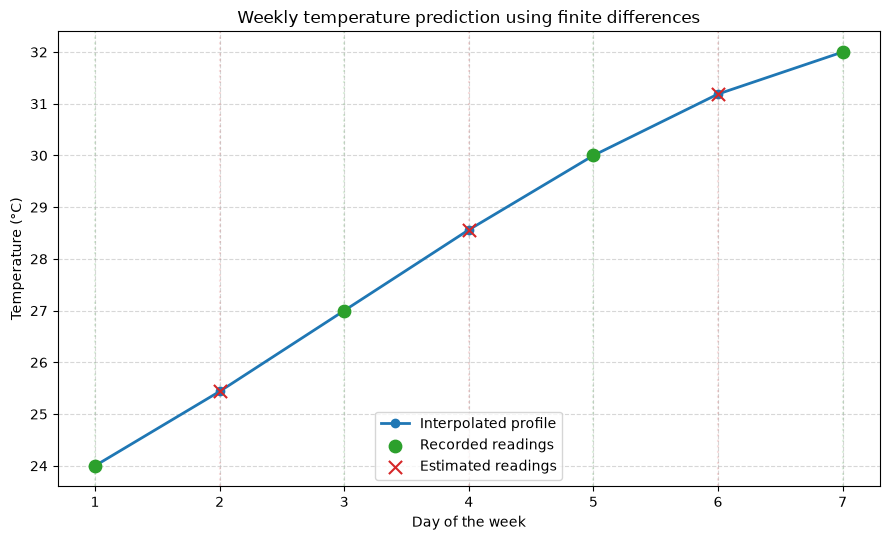

In [11]:
weekly_temperatures = weekly_report["Temperature (°C)"].to_numpy()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(all_days, weekly_temperatures, marker="o", linewidth=2, label="Interpolated profile")
ax.scatter(days, temperatures, s=80, color="tab:green", label="Recorded readings", zorder=3)
ax.scatter(missing_days, [forward_estimates[day] for day in missing_days], s=90, marker="x", color="tab:red", label="Estimated readings", zorder=4)
for day in days:
    ax.axvline(day, color="tab:green", alpha=0.15, linestyle=":")
for day in missing_days:
    ax.axvline(day, color="tab:red", alpha=0.15, linestyle=":")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Weekly temperature prediction using finite differences")
ax.set_xticks(all_days)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()


## 13. Discussion

- **Equal spacing:** Newton's forward/backward formulas require constant $h$. Unequal spacing requires another method, such as Newton divided differences.
- **Formula choice:** Forward differences are convenient near the beginning; backward differences are convenient near the end. With all nodes included, both evaluate the same polynomial.
- **Accuracy:** Independent polynomial tests recover known functions through degree three to floating-point precision. The fixed-target spacing study confirms the expected $O(h^4)$ rate for cubic interpolation, while the terms experiment shows how truncation and rounded tabulated values affect the estimate.
- **Stability and measurement error:** Errors in measured temperatures propagate into differences and interpolated values. The sensitivity table illustrates the effect of a small perturbation. High-degree polynomials may oscillate; extrapolation is generally less reliable than interpolation.
- **Rounding:** Binary floating-point arithmetic introduces small errors. The sine example uses values rounded to six decimal places [1], so its term contributions reflect rounded input data. Elsewhere, retaining full precision during calculations and rounding only displayed results limits avoidable error.

This dataset is hypothetical and contains only four known readings. Real temperature prediction would require real measurements, an uncertainty study, and validation on observations not used to fit the interpolant.

### Extensions and limitations

With more than four readings, a nonzero next difference would show that the data are not represented exactly by the current cubic and motivate considering additional terms or another model. Real temperature readings are noisy; for repeated measurements, smoothing or a least-squares model may be more appropriate than exact interpolation.


## 14. Conclusion

For this hypothetical dataset, Newton's forward finite-difference interpolation estimates **25.4375°C on Day 2**, **28.5625°C on Day 4**, and **31.1875°C on Day 6**. The difference table exposes the calculations, and the interpolation formula produces the estimates.

Independent analytical tests, reference examples [1], input-validation tests, a term-by-term accuracy experiment, and comparison with Newton's backward formula demonstrate the method's correctness and limitations. Using the six-decimal sine table, the term-by-term experiment obtains a $\Delta^2 f_0$ contribution of approximately $0.000248$; this contribution is distinct from the total interpolation error. The fixed-target spacing study is consistent with the classical $O(h^4)$ remainder for a cubic interpolant. Overall, the method provides estimates for missing readings in the hypothetical, equally spaced weekly dataset.

## References

[1] 4SCS2102, *Numerical Analysis and Computation: Interpolation Using Finite Differences*, course handout, 1 September 2025.
